In [161]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import src.helper
import src.plots
import src.spectra

In [162]:
MEASUREMENT_PERIOD = 1 / 12  # 2 hour timestep
TIME_BANDWIDTH_PRODUCT = 3

SEMIDIURNAL_TIDAL_CONSTITUENTS = src.helper.get_tidal_frequencies_in_hours(tide_type="continuum")
# # sort the constituents in descending order after their tidal periods
# # This is important for finding overlapping tidal peaks
SEMIDIURNAL_TIDAL_CONSTITUENTS = dict(
    sorted(SEMIDIURNAL_TIDAL_CONSTITUENTS.items(), key=lambda x: x[1], reverse=True)
)

CORIOLIS_FREQUENCY_IN_CPD_AT_C = src.helper.get_coriolis_frequency(
    -63.66, unit="cpd", absolute=True
)

In [163]:
# load all 7 moorings as dataframes
list_of_moorings = src.helper.load_pickle(name="../../data/mooring/list_of_moorings.pkl")
mooring_C = src.helper.load_pickle(name="../preprocessing/mooring_C.pkl")
region_categorization = pd.read_csv("../../derived_data/rcm_infos.csv", index_col=0)
names = ["A", "B", "C", "D", "E", "F", "G"]
moorings = {}
for name, mooring in zip(names, list_of_moorings, strict=False):
    moorings[name] = mooring.set_index("time")
    print(mooring.location, list(mooring.columns))

(-63.40,-52.29) ['time', '299', '505', '614']
(-63.51,-51.64) ['time', '1318', '1513', '1625']
(-63.66,-50.81) ['time', '2143', '2350', '750']
(-63.78,-50.09) ['time', '2400', '2615', '2724']
(-63.92,-49.27) ['time', '3036', '3299', '3358']
(-64.07,-48.38) ['time', '3835']
(-64.22,-47.49) ['time', '4120', '4160']


In [164]:
def find_latest_start(moorings):
    starttimes = []
    for i, (name, mooring) in enumerate(moorings.items()):
        for j, col in enumerate(mooring.columns):
            if name == "C":
                series = pd.Series(
                    index=mooring_C[f"time_{col}"].values, data=mooring_C[col].values
                )
            else:
                series = mooring[col]
            starttimes.append(series.index[0])

    latest_start = np.max(np.array(starttimes))
    return latest_start


common_start_time = pd.to_datetime(find_latest_start(moorings)).round("h")
print(f"{common_start_time = }")

common_start_time = Timestamp('2017-01-28 12:00:00')


In [165]:
def get_integration_intervals_for_tidal_peaks(freq, P, tidal_periods):
    integration_indices_intervals = []

    # get interval of width 2P for each tidal frequency
    for tidal_period in tidal_periods:
        tidal_freq_in_cpd = 24 / tidal_period
        tidal_index = np.argmin(np.abs(freq - (tidal_freq_in_cpd)))
        width = (tidal_index - P, tidal_index + P + 1)
        integration_indices_intervals.append(width)

    # because the peaks all have the same width 2P, I can check the ascending order
    # by checking if the start or the end points are in ascending order. I test here both to be extra sure
    def is_monotonic_increasing(L):
        return all(x <= y for x, y in zip(L, L[1:], strict=False))

    # slicing a list of tuples is complicated
    interval_start_points = list(zip(*integration_indices_intervals, strict=False))[0]
    try:
        assert is_monotonic_increasing(interval_start_points)
    except AssertionError as e:
        print(f"{interval_start_points =}")
        raise e

    # slicing a list of tuples is complicated
    interval_end_points = list(zip(*integration_indices_intervals, strict=False))[1]
    try:
        assert is_monotonic_increasing(interval_end_points)
    except AssertionError as e:
        print(f"{interval_end_points =}")
        raise e

    # check intervals for overlaps until none are found
    while True:
        Overlap = False
        # Iteration is over a copy to not change the object iterated over
        for i, interval in enumerate(integration_indices_intervals.copy()):
            if i + 1 == len(integration_indices_intervals):
                break
            next_interval = integration_indices_intervals[i + 1]

            start1, end1 = interval
            start2, end2 = next_interval

            if end1 >= start2 and end2 >= start1:
                Overlap = True
                integration_indices_intervals[i] = (start1, end2)
                integration_indices_intervals[i + 1] = (start1, end2)

        # remove duplicated intervals
        # by creating a dictionary with the tuples as keys and None values and then converting back to list
        integration_indices_intervals = list(dict.fromkeys(integration_indices_intervals))

        if not Overlap:
            break
    return integration_indices_intervals

In [166]:
for i, (name, mooring) in enumerate(moorings.items()):
    for j, col in enumerate(mooring.columns):
        if name != "C" or col != str(2350):
            continue

        if name == "C":
            series = pd.Series(index=mooring_C[f"time_{col}"].values, data=mooring_C[col].values)
            series = series[series.index.dropna()]
            assert series.index.is_monotonic_increasing
            series = series.loc[pd.to_datetime(common_start_time) :]
            mooring_id = i
            col_name = name
            if int(col) == 750:
                mooring_id = -1
                col_name = "control"
        else:
            continue
            # series = mooring[col]
            # series = series.loc[pd.to_datetime(common_start_time):]
            # mooring_id = i
            # col_name=name

        # nsquared_time_series = nsquared_data_at_measurements[name][col]

        series = series.dropna()
        # coriolis_frequency_in_cpd = src.helper.get_coriolis_frequency(mooring.location.lat, unit="cpd", absolute=True)

        print(name, col)
        count = 0
        number_of_days: int = 30

        chunk_bounds = []
        for run, chunk in enumerate(series.rolling(window=f"{number_of_days}D", center=True)):
            if run % (12 * 5) != 0:
                continue  # skip 5 days every loop

            # print(len(chunk), int(number_of_days/MEASUREMENT_PERIOD))
            if len(chunk) < int(number_of_days / MEASUREMENT_PERIOD):
                continue  # skip windows with not enough data points

            chunk = chunk.resample("D").mean()
            chunk_bounds.append((chunk.index[0], chunk.index[-1]))

C 2350


In [167]:
measured_tidal_energy_df = pd.DataFrame(index=chunk_bounds)

for i, (name, mooring) in enumerate(moorings.items()):
    for j, col in enumerate(mooring.columns):
        # if name != "C" or col != str(2350):
        #    continue

        if name == "C":
            series = pd.Series(index=mooring_C[f"time_{col}"].values, data=mooring_C[col].values)
            series = series[series.index.dropna()]
            assert series.index.is_monotonic_increasing
            series = series.loc[pd.to_datetime(common_start_time) :]
            mooring_id = i
            col_name = name
            if int(col) == 750:
                mooring_id = -1
                col_name = "control"
        else:
            continue
            # series = mooring[col]
            # series = series.loc[pd.to_datetime(common_start_time):]
            # mooring_id = i
            # col_name=name

        series = series.dropna()
        # coriolis_frequency_in_cpd = src.helper.get_coriolis_frequency(mooring.location.lat, unit="cpd", absolute=True)
        print(name, col)

        chunks_tidal_energy = []
        for chunk_bound in chunk_bounds:
            chunk = series.loc[chunk_bound[0] : chunk_bound[1]]

            if len(chunk) < int(number_of_days / MEASUREMENT_PERIOD) - 5:
                print(col, len(chunk), int(number_of_days / MEASUREMENT_PERIOD))
                chunks_tidal_energy.append(np.nan)
                continue

            # Calculate resolved horizontal kinetic energy spectrum between f and N (again)
            complex_velocity_array = chunk.values
            freq, velocity_spectrum = src.spectra.total_multitaper(
                complex_velocity_array, dt=1 / 12, P=TIME_BANDWIDTH_PRODUCT
            )

            # The integral over the whole integral yield the variance of the velocity
            # The energy of a signal of mean 0 is then half the variance
            # Therefore we divide by 2 to have the correct physical interpretation of the spectrum
            resolved_HKE_spectrum = velocity_spectrum / 2
            # kinetic_psd
            assert not np.any(np.isnan(resolved_HKE_spectrum))

            horizontal_kinetic_energy_per_peak = []  # no direct physical meaning, as it does not differentiate between barotropic and baroclinic tides
            # calculate integration intervals for the tidal peaks
            integration_indices_intervals = get_integration_intervals_for_tidal_peaks(
                freq,
                P=TIME_BANDWIDTH_PRODUCT,
                tidal_periods=SEMIDIURNAL_TIDAL_CONSTITUENTS.values(),
            )

            # iterate over the tidal peaks and calculate energy per peak
            for interval_tuple in integration_indices_intervals:
                a = freq[interval_tuple[0]]
                try:
                    b = freq[interval_tuple[1]]
                except IndexError:
                    b = freq[-1]
                peak_integral = src.spectra.integrate_psd_interval(
                    freq, resolved_HKE_spectrum, a=a, b=b
                )
                horizontal_kinetic_energy_per_peak.append(peak_integral)

            chunks_tidal_energy.append(np.sum(horizontal_kinetic_energy_per_peak))

        measured_tidal_energy_df[col] = chunks_tidal_energy

C 2143
2143 354 360
2143 339 360
2143 279 360
2143 219 360
2143 159 360
2143 99 360
2143 39 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
2143 0 360
C 2350
2350 354 360
C 750
750 354 360
750 336 360
750 276 360
750 216 360
750 156 360
750 96 360
750 36 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750 0 360
750

In [168]:
measured_tidal_energy_df

,2143,2350,750
"(2017-01-28 00:00:00, 2017-02-27 00:00:00)",NaN,NaN,NaN
"(2017-02-02 00:00:00, 2017-03-04 00:00:00)",0.000713,0.000660,0.000264
"(2017-02-07 00:00:00, 2017-03-09 00:00:00)",0.000760,0.000663,0.000275
"(2017-02-12 00:00:00, 2017-03-14 00:00:00)",0.000703,0.000618,0.000258
"(2017-02-17 00:00:00, 2017-03-19 00:00:00)",0.000755,0.000874,0.000275
...,...,...,...
"(2018-12-09 00:00:00, 2019-01-08 00:00:00)",NaN,0.000426,NaN
"(2018-12-14 00:00:00, 2019-01-13 00:00:00)",NaN,0.000513,NaN
"(2018-12-19 00:00:00, 2019-01-18 00:00:00)",NaN,0.000589,NaN
"(2018-12-24 00:00:00, 2019-01-23 00:00:00)",NaN,0.000644,NaN


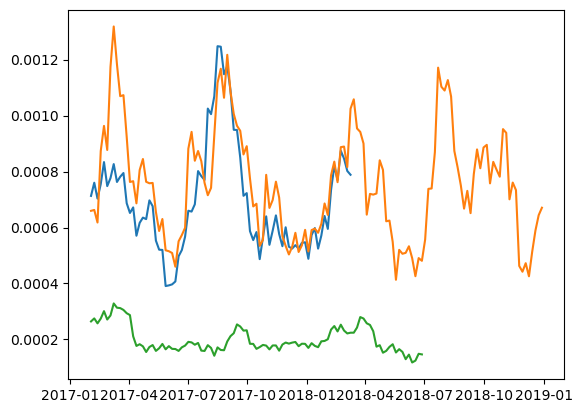

In [169]:
for col in measured_tidal_energy_df.columns:
    plt.plot(np.array(chunk_bounds)[:, 0], measured_tidal_energy_df[col])

In [170]:
cats_df = pd.read_pickle("../../data/from_Pinner_et_al_2025/cats_data.pickle")
cats_df = cats_df.set_index(pd.to_datetime(cats_df["time"])).drop(columns="time")
# cats_mean_HKE = cats_df.loc[:, cats_df.columns != 'time'].abs().pow(2).mean()
# cats_lons = [_[1] for _ in cats_df.loc[:, cats_df.columns != 'time']
# cats_df
cats_at_C = cats_df[(-63.78, -50.09)]
cats_at_C

time
2017-01-25 00:00:00   -0.010797+0.042936j
2017-01-25 01:00:00   -0.007679+0.032776j
2017-01-25 02:00:00   -0.004500+0.020619j
2017-01-25 03:00:00   -0.001361+0.009173j
2017-01-25 04:00:00    0.001733+0.000596j
                              ...        
2020-02-23 18:59:59   -0.010771-0.028254j
2020-02-23 19:59:59   -0.013824-0.004929j
2020-02-23 20:59:59   -0.014678+0.019173j
2020-02-23 21:59:59   -0.013421+0.038999j
2020-02-23 22:59:59   -0.010583+0.050527j
Name: (-63.78, -50.09), Length: 27000, dtype: complex128

In [171]:
def get_cats_chunk(chunk_time_index, cats_time_series):

    try:
        # cats begins before the requested chunk
        assert cats_time_series.index[0] <= chunk_time_index[0]
        # cats ends after the requested chunk
        assert cats_time_series.index[-1] >= chunk_time_index[-1]
        return cats_time_series.loc[chunk_time_index[0] : chunk_time_index[-1]]

    # requested chunk is outside the given time series
    except AssertionError as e:
        print(np.abs(cats_time_series.index[0] - chunk_time_index[0]))
        print(np.abs(cats_time_series.index[-1] - chunk_time_index[-1]))
        raise e
        # return np.nan

In [172]:
cats_at_C = cats_df[(-63.78, -50.09)]
cats_chunk_semidiurnal_barotropic_energies = []
for chunk_bound in chunk_bounds:
    cats_uv = get_cats_chunk(chunk_bound, cats_at_C)
    cats_freq, cats_velocity_spectrum = src.spectra.total_multitaper(
        cats_uv.values, dt=1 / 24, P=TIME_BANDWIDTH_PRODUCT
    )  # IMPORTANT: 1 hour timestep
    # The integral over the whole integral yields the variance of the velocity
    # The energy of a signal of mean 0 is then half the variance
    # Therefore, we divide by 2 to have the correct physical interpretation of the spectrum
    cats_HKE_spectrum = cats_velocity_spectrum / 2
    # == barotropic tidal energy ==
    cats_semidiurnal_barotropic_energy_between_f_and_N = src.spectra.integrate_psd_interval(
        cats_freq, cats_HKE_spectrum, a=CORIOLIS_FREQUENCY_IN_CPD_AT_C, b=20
    )
    cats_chunk_semidiurnal_barotropic_energies.append(
        cats_semidiurnal_barotropic_energy_between_f_and_N
    )

pd.Series(index=chunk_bounds, data=cats_chunk_semidiurnal_barotropic_energies)

(2017-01-28 00:00:00, 2017-02-27 00:00:00)    0.000181
(2017-02-02 00:00:00, 2017-03-04 00:00:00)    0.000201
(2017-02-07 00:00:00, 2017-03-09 00:00:00)    0.000214
(2017-02-12 00:00:00, 2017-03-14 00:00:00)    0.000196
(2017-02-17 00:00:00, 2017-03-19 00:00:00)    0.000221
                                                ...   
(2018-12-09 00:00:00, 2019-01-08 00:00:00)    0.000138
(2018-12-14 00:00:00, 2019-01-13 00:00:00)    0.000156
(2018-12-19 00:00:00, 2019-01-18 00:00:00)    0.000155
(2018-12-24 00:00:00, 2019-01-23 00:00:00)    0.000135
(2018-12-29 00:00:00, 2019-01-28 00:00:00)    0.000161
Length: 141, dtype: float64

In [173]:
best_guess_barotropic_energy_at_C = pd.Series(
    index=chunk_bounds,
    data=np.nanmin(
        [measured_tidal_energy_df["750"].values, cats_chunk_semidiurnal_barotropic_energies], axis=0
    ),
)
best_guess_barotropic_energy_at_C

(2017-01-28 00:00:00, 2017-02-27 00:00:00)    0.000181
(2017-02-02 00:00:00, 2017-03-04 00:00:00)    0.000201
(2017-02-07 00:00:00, 2017-03-09 00:00:00)    0.000214
(2017-02-12 00:00:00, 2017-03-14 00:00:00)    0.000196
(2017-02-17 00:00:00, 2017-03-19 00:00:00)    0.000221
                                                ...   
(2018-12-09 00:00:00, 2019-01-08 00:00:00)    0.000138
(2018-12-14 00:00:00, 2019-01-13 00:00:00)    0.000156
(2018-12-19 00:00:00, 2019-01-18 00:00:00)    0.000155
(2018-12-24 00:00:00, 2019-01-23 00:00:00)    0.000135
(2018-12-29 00:00:00, 2019-01-28 00:00:00)    0.000161
Length: 141, dtype: float64

In [174]:
best_guess_barotropic_energy_at_C.to_csv("./best_guess_barotropic_energy_at_C.csv")

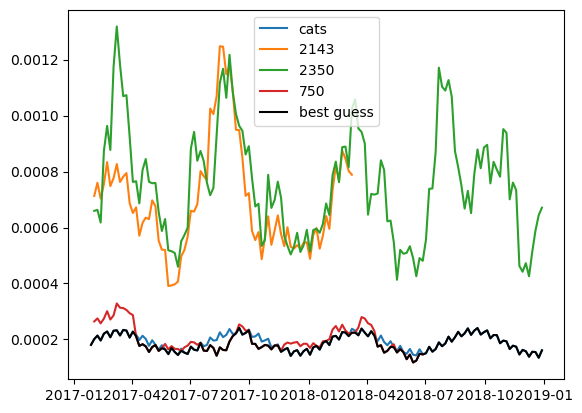

In [175]:
plt.plot(np.array(chunk_bounds)[:, 0], cats_chunk_semidiurnal_barotropic_energies, label="cats")
for col in measured_tidal_energy_df.columns:
    plt.plot(np.array(chunk_bounds)[:, 0], measured_tidal_energy_df[col], label=col)
plt.plot(
    np.array(chunk_bounds)[:, 0],
    best_guess_barotropic_energy_at_C,
    label="best guess",
    color="black",
)
plt.legend()